
# 1. Exploratory Data Analysis (EDA)

## 1.1 Objective

The objective of this notebook is to explore the UCI Heart Disease Cleveland
dataset before developing a machine learning classification model.

The analysis includes:
- Loading and inspecting the dataset.
- Examining descriptive statistics and data quality.
- Identifying missing values and duplicate records.
- Visualizing feature distributions.
- Studying correlations between variables.
- Understanding the original and binary target distributions.

EDA helps identify data-quality issues and informs preprocessing and
model-development decisions.

**Dataset:** UCI Heart Disease — Processed Cleveland Database.



## 1.2 Import Libraries and Load the Dataset

We use Pandas to load and inspect the dataset, Matplotlib and Seaborn
to create visualizations, and Pathlib to construct file paths.

The Cleveland data file does not contain column headers. Therefore, we
assign the documented 13 predictor names and one target name while loading it.
The `?` marker is interpreted as a missing value.


In [42]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Resolve the project root from the notebook location.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_FILE = (
    PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data"
)
SCREENSHOT_DIR = PROJECT_ROOT / "screenshots"
SCREENSHOT_DIR.mkdir(parents=True, exist_ok=True)

COLUMN_NAMES = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    DATA_FILE,
    header=None,
    names=COLUMN_NAMES,
    na_values=["?"],
    skipinitialspace=True
)

for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

sns.set_theme(style="whitegrid")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully.
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



## 1.3 Dataset Overview

This section examines the dataset's structure and basic statistical
properties.

The `shape` reports the number of observations and columns.
Descriptive statistics summarize numerical values using measures such
as the mean, standard deviation, minimum, and maximum.

These summaries help identify unusual values and understand the scale
of individual features before preprocessing.


In [43]:

print("Dataset dimensions:", df.shape)

print("\nColumn data types and non-null counts:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T.round(2))


Dataset dimensions: (303, 14)

Column data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2



## 1.4 Data Quality Assessment

Missing values can prevent some machine learning algorithms from
training successfully. Duplicate observations can also affect model
evaluation if they are not examined carefully.

We calculate missing values for each column and count exact duplicate
rows. Missing values will be handled later in a reusable preprocessing
pipeline to avoid data leakage between training and validation sets.


In [44]:

missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]

print("Missing values by column:")
display(missing_counts.to_frame("missing_count"))

print("Total missing cells:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values by column:


,missing_count
ca,4
thal,2


Total missing cells: 6
Duplicate rows: 0



## 1.5 Feature Distribution Analysis

Histograms are used to examine the distributions of selected numerical
features: age, resting blood pressure, serum cholesterol, maximum heart
rate, and oldpeak.

The plots help identify skewness, spread, possible outliers, and
differences in measurement ranges. These observations can guide
preprocessing decisions.


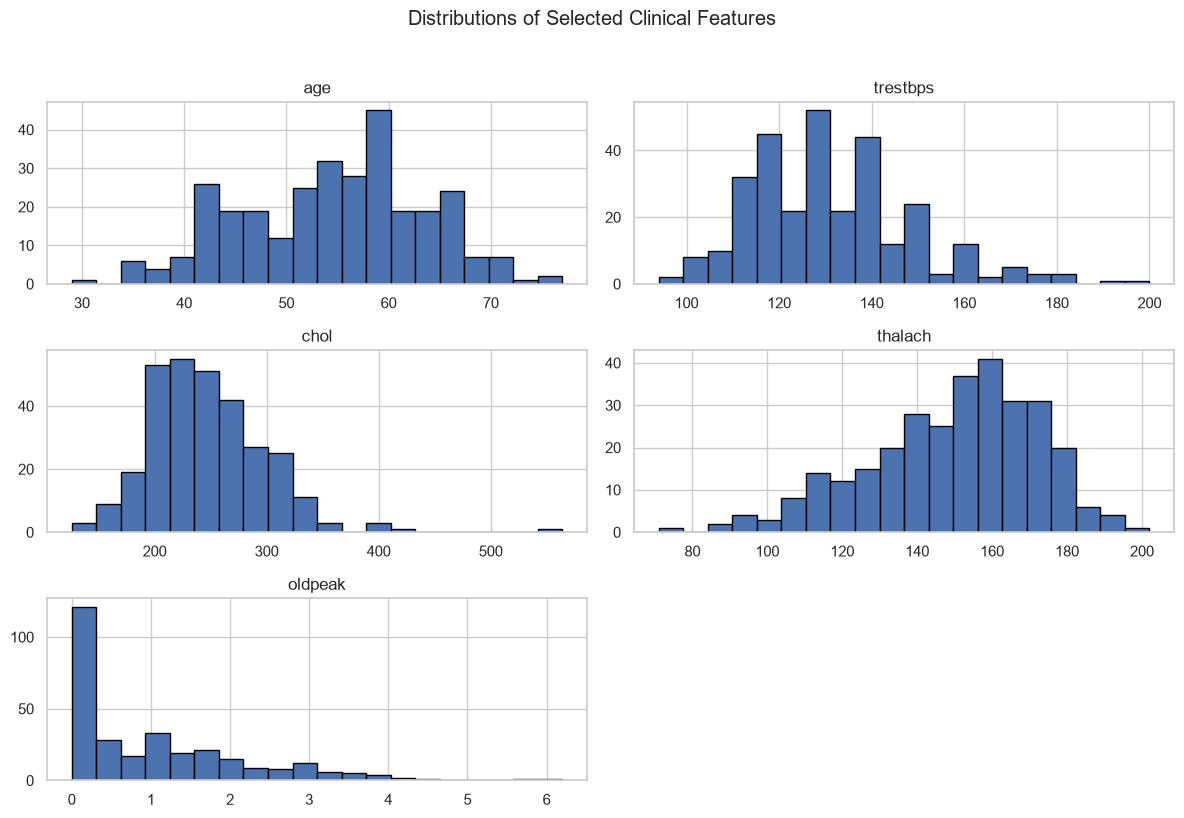

In [45]:

numeric_columns = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

df[numeric_columns].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Selected Clinical Features", y=1.02)
plt.tight_layout()

plt.savefig(
    SCREENSHOT_DIR / "01_feature_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



## 1.6 Correlation Analysis

A correlation matrix summarizes pairwise linear relationships between
numeric columns. The heatmap displays these correlations using color
intensity and annotated values.

Correlations can help identify related variables, but they do not prove
causation. In addition, some columns are categorical codes, so their
Pearson correlations should be interpreted cautiously.


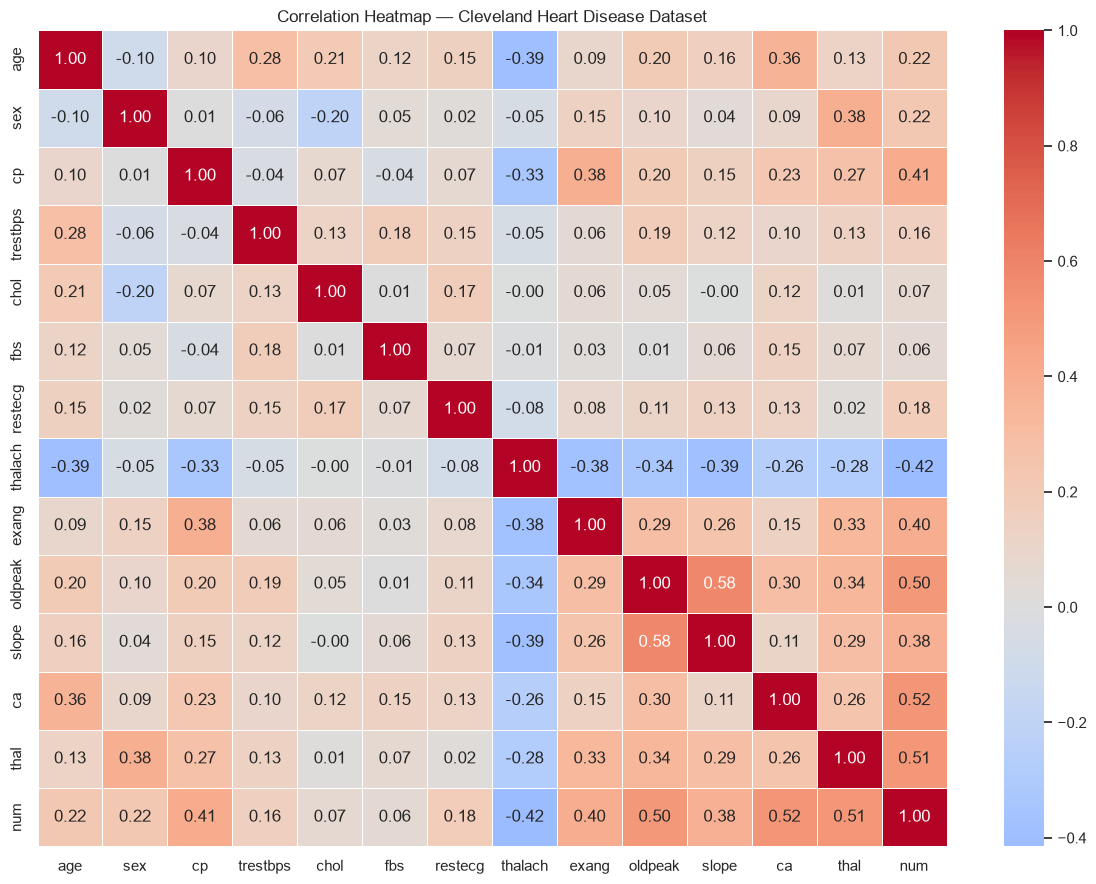

In [46]:

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap — Cleveland Heart Disease Dataset")
plt.tight_layout()

plt.savefig(
    SCREENSHOT_DIR / "02_correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



## 1.7 Original Target Distribution

The original target column `num` uses five values, from 0 to 4.
The value 0 represents the absence of diagnosed heart disease, while
values 1 through 4 represent different levels of disease presence.

This section examines the number of observations in each original
target category before transforming the problem into binary classification.


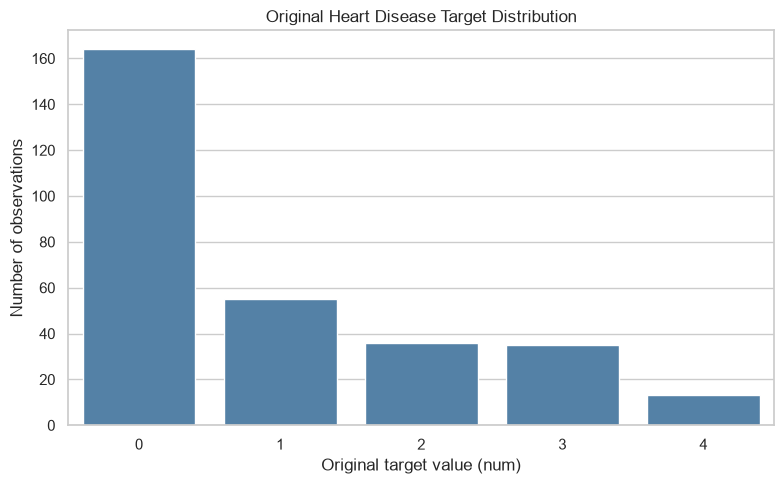

,count
num,
0,164
1,55
2,36
3,35
4,13


In [47]:

target_counts = df["num"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="num",
    order=[0, 1, 2, 3, 4],
    color="steelblue"
)

ax.set_title("Original Heart Disease Target Distribution")
ax.set_xlabel("Original target value (num)")
ax.set_ylabel("Number of observations")

plt.tight_layout()

plt.savefig(
    SCREENSHOT_DIR / "03_original_target_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(target_counts.to_frame("count"))



## 1.8 Binary Target Transformation

The assignment requires a binary classification model. We therefore
transform the original target into a new column called `target`.

- `0`: Absence of heart disease (original `num = 0`).
- `1`: Presence of heart disease (original `num > 0`).

The original `num` column is retained for traceability, but the new
`target` column will be used as the prediction label in model development.

This transformation follows the assignment's binary prediction objective.
It does not mean that the model is suitable for clinical diagnosis.


Binary target counts:


,count
target,
Absence,164
Presence,139


Binary target proportions:


,proportion
target,
Absence,0.541254
Presence,0.458746


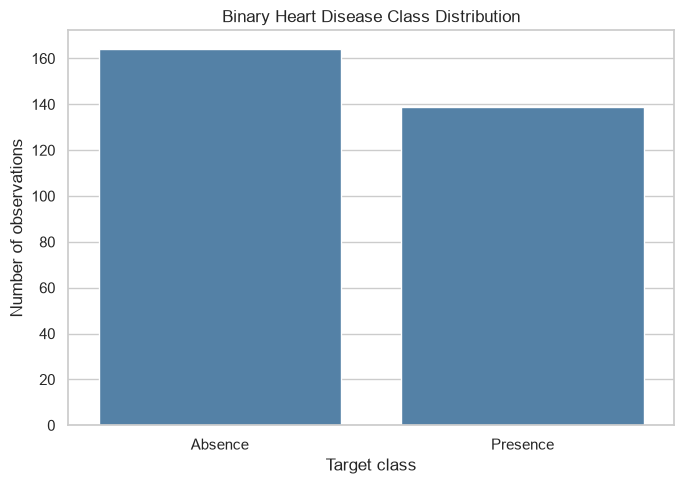

In [48]:

df["target"] = (df["num"] > 0).astype(int)

binary_counts = df["target"].value_counts().sort_index()

print("Binary target counts:")
display(
    binary_counts.rename({
        0: "Absence",
        1: "Presence"
    }).to_frame("count")
)

print("Binary target proportions:")
display(
    df["target"]
    .value_counts(normalize=True)
    .sort_index()
    .rename({
        0: "Absence",
        1: "Presence"
    })
    .to_frame("proportion")
)

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="target",
    order=[0, 1],
    color="steelblue"
)

ax.set_title("Binary Heart Disease Class Distribution")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of observations")
ax.set_xticks([0, 1], ["Absence", "Presence"])

plt.tight_layout()

plt.savefig(
    SCREENSHOT_DIR / "04_binary_target_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()



## 1.9 EDA Findings and Discussion

### Feature distributions
The histograms show that the selected clinical variables have different
distributions. Cholesterol and oldpeak show right-skewness, while age
and maximum heart rate are distributed across a range of values.
Potentially extreme observations should be investigated rather than
removed automatically.

### Correlation analysis
The correlation heatmap indicates associations among several features.
The strongest displayed off-diagonal relationship is between oldpeak
and slope (approximately 0.58). The original target num is positively
correlated with ca (approximately 0.52) and negatively correlated with
thalach (approximately -0.42). These results are exploratory and do not
establish causation.

### Target distribution
The original target contains five classes. For binary classification,
the target was transformed so that 0 represents absence of heart disease
and 1 represents presence. The resulting dataset contains 164 absence
records and 139 presence records.

### Data quality and preprocessing implications
The dataset contains 303 records and 14 original columns. Six missing
cells were identified: four in ca and two in thal. No exact duplicate
rows were detected. Missing values will be handled within the model
preprocessing pipeline to maintain reproducibility and avoid data leakage.

### Conclusion
EDA provides an initial understanding of feature distributions, missing
values, associations and target balance. The next stage will implement
a reproducible preprocessing pipeline and evaluate classification models.
